# Paso 4 · Decibelios y escala logarítmica (con Python)

Notebook del **Paso 4**: por qué se usan los decibelios, cómo se **suman** las curvas de los factores y qué hace un retardo.

| Concepto matemático | Concepto de programación |
|---|---|
| $\text{dB}=20\log_{10}|P|$ y la tabla de valores clave | funciones y comprobación con `assert` |
| producto de factores = suma de dB | vectorización y composición de funciones |
| los cuatro bloques elementales | diccionario de funciones, bucle de dibujo |
| asíntotas de Bode (tramos rectos) | `np.where` / `np.maximum` |
| retardo puro $e^{-sT}$ | fase lineal, comprobación de $-57.3^\circ$ y $-573^\circ$ |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

AZUL, NARANJA, TINTA, GRIS = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e3e2de", "axes.axisbelow": True,
                     "font.size": 10})
np.set_printoptions(precision=4, suppress=True)

In [2]:
db = lambda z: 20 * np.log10(np.abs(z))
fase_deg = lambda z: np.degrees(np.unwrap(np.angle(z)))
w = np.logspace(-2, 3, 2000)       # 5 décadas, equiespaciadas en log

## 1. La tabla de decibelios

$|P|_{\rm dB}=20\log_{10}|P|$. Hay que sabérsela: $\times2\to+6$ dB, $\times10\to+20$ dB, $\times\frac1{\sqrt2}\to-3$ dB.

In [3]:
for m in [0.1, 0.5, 1/np.sqrt(2), 1, np.sqrt(2), 2, 10, 100]:
    print(f"|P| = {m:8.4f}  ->  {db(m):8.3f} dB")
assert np.isclose(db(2), 6.0206, atol=1e-3) and np.isclose(db(10), 20)

|P| =   0.1000  ->   -20.000 dB
|P| =   0.5000  ->    -6.021 dB
|P| =   0.7071  ->    -3.010 dB
|P| =   1.0000  ->     0.000 dB
|P| =   1.4142  ->     3.010 dB
|P| =   2.0000  ->     6.021 dB
|P| =  10.0000  ->    20.000 dB
|P| = 100.0000  ->    40.000 dB


## 2. Un producto se convierte en una suma

$\log(ab)=\log a+\log b$: la magnitud en dB de un producto de factores es la **suma** de las magnitudes en dB, y la fase también se suma. Lo comprobamos con $P(s)=\dfrac{10(1+s/2)}{s(1+s/20)}$ en $\omega=5$:

In [4]:
w0 = 5.0; s = 1j * w0
factores = {"K = 10": 10 + 0j, "1/s": 1 / s, "1 + s/2": 1 + s / 2, "1/(1 + s/20)": 1 / (1 + s / 20)}
tot_db = tot_fase = 0
for n, f in factores.items():
    print(f"{n:>14}: {db(f):8.3f} dB   {np.degrees(np.angle(f)):8.3f}°")
    tot_db += db(f); tot_fase += np.degrees(np.angle(f))
P = 10 * (1 + s / 2) / (s * (1 + s / 20))
print(f"{'suma':>14}: {tot_db:8.3f} dB   {tot_fase:8.3f}°")
print(f"{'P(jw) directa':>14}: {db(P):8.3f} dB   {np.degrees(np.angle(P)):8.3f}°")
assert np.isclose(tot_db, db(P)) and np.isclose(tot_fase, np.degrees(np.angle(P)))

        K = 10:   20.000 dB      0.000°
           1/s:  -13.979 dB    -90.000°
       1 + s/2:    8.603 dB     68.199°
  1/(1 + s/20):   -0.263 dB    -14.036°
          suma:   14.361 dB    -35.838°
 P(jw) directa:   14.361 dB    -35.838°


## 3. Los cuatro bloques elementales

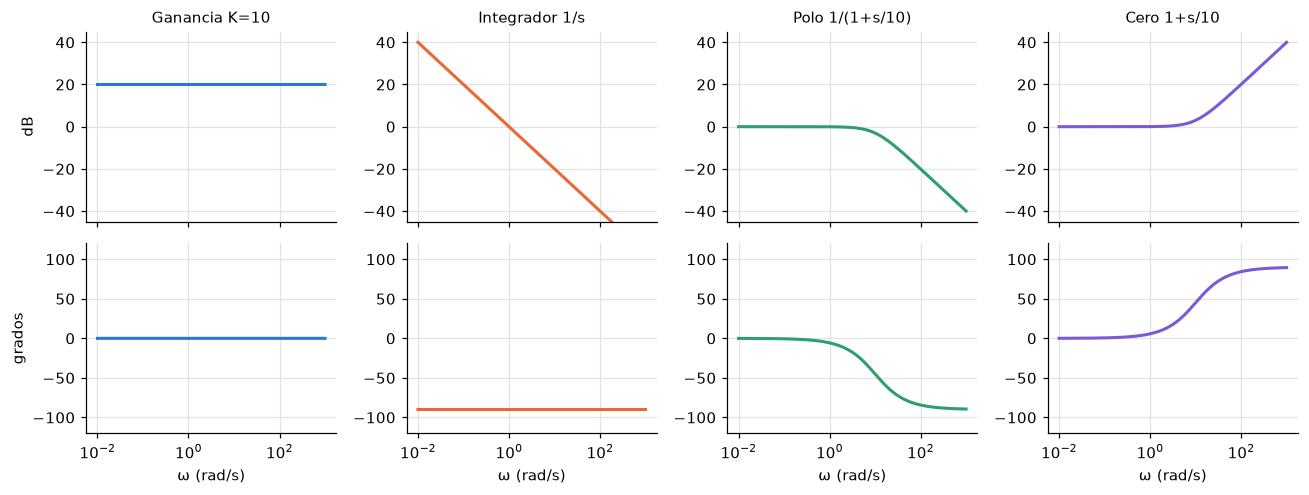

polo en w = 10: -3.01 dB, -45.0°   (-3 dB y -45°)


In [5]:
bloques = [("Ganancia K=10", lambda s: 10 + 0*s, AZUL), ("Integrador 1/s", lambda s: 1/s, NARANJA),
           ("Polo 1/(1+s/10)", lambda s: 1/(1 + s/10), "#2f9e6e"), ("Cero 1+s/10", lambda s: 1 + s/10, "#7a5bd6")]
fig, ax = plt.subplots(2, 4, figsize=(12, 4.6), sharex=True)
for k, (t, f, c) in enumerate(bloques):
    z = f(1j * w)
    ax[0, k].semilogx(w, db(z), color=c, lw=2); ax[1, k].semilogx(w, fase_deg(z), color=c, lw=2)
    ax[0, k].set_title(t, fontsize=10); ax[0, k].set_ylim(-45, 45); ax[1, k].set_ylim(-120, 120)
    ax[1, k].set_xlabel("ω (rad/s)")
ax[0, 0].set_ylabel("dB"); ax[1, 0].set_ylabel("grados")
fig.tight_layout(); plt.show()
z = bloques[2][1](10j)
print(f"polo en w = 10: {db(z):.2f} dB, {np.degrees(np.angle(z)):.1f}°   (-3 dB y -45°)")

## 4. Dibujar a mano: las asíntotas

Cada **cero** en $\omega_z$ suma $+20$ dB/dec a partir de $\omega_z$; cada **polo** en $\omega_p$ resta $20$ dB/dec; cada integrador es una recta de $-20$ dB/dec que pasa por 0 dB en $\omega=1$. Con `np.where` se programa sin bucles:

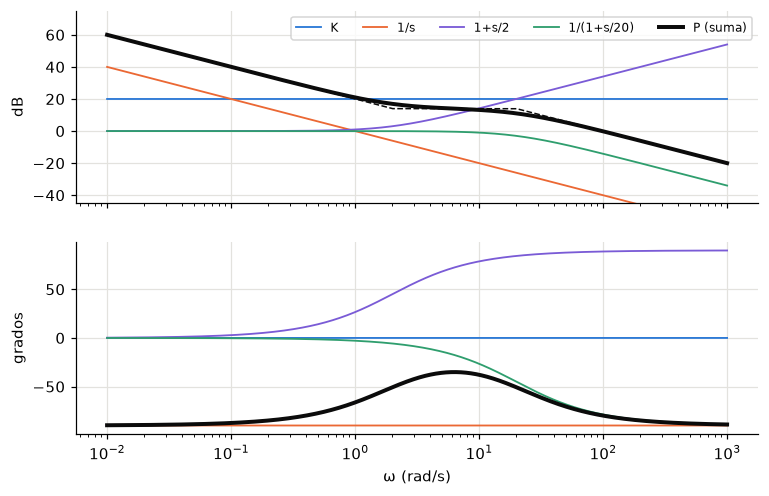

w =   0.1: exacta   40.01 dB | asíntota   40.00 dB
w =     2: exacta   16.95 dB | asíntota   13.98 dB
w =    20: exacta   11.01 dB | asíntota   13.98 dB
w =   200: exacta   -6.06 dB | asíntota   -6.02 dB


In [6]:
def asintota_db(w, K=1, integradores=0, ceros=(), polos=()):
    """Magnitud asintótica (dB) de K (1+s/z1)... / (s^n (1+s/p1)...)."""
    y = 20*np.log10(K) - 20*integradores*np.log10(w)
    for z in ceros: y = y + np.where(w > z, 20*np.log10(w/z), 0)
    for p in polos: y = y - np.where(w > p, 20*np.log10(w/p), 0)
    return y

Pej = lambda s: 10*(1 + s/2) / (s*(1 + s/20))
fig, (m, p) = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
for lab, f, c in [("K", lambda s: 10+0*s, AZUL), ("1/s", lambda s: 1/s, NARANJA),
                  ("1+s/2", lambda s: 1+s/2, "#7a5bd6"), ("1/(1+s/20)", lambda s: 1/(1+s/20), "#2f9e6e")]:
    m.semilogx(w, db(f(1j*w)), color=c, lw=1.2, label=lab); p.semilogx(w, fase_deg(f(1j*w)), color=c, lw=1.2)
m.semilogx(w, db(Pej(1j*w)), color=TINTA, lw=2.6, label="P (suma)"); p.semilogx(w, fase_deg(Pej(1j*w)), color=TINTA, lw=2.6)
m.semilogx(w, asintota_db(w, 10, 1, ceros=[2], polos=[20]), "--", color=TINTA, lw=1)
m.set_ylim(-45, 75); m.set_ylabel("dB"); p.set_ylabel("grados"); p.set_xlabel("ω (rad/s)"); m.legend(ncol=5, fontsize=8)
plt.show()
for wv in (0.1, 2, 20, 200):
    print(f"w = {wv:>5}: exacta {db(Pej(1j*wv)):7.2f} dB | asíntota {float(asintota_db(wv, 10, 1, [2], [20])):7.2f} dB")

En los codos ($\omega=2$ y $\omega=20$) la curva exacta se separa $\pm3$ dB de las rectas; lejos de ellos coinciden.

## 5. Un retardo puro: magnitud intacta, fase que se pierde

$D(s)=e^{-sT}$ con $T=0.1$ s: $|D(j\omega)|=1$ (0 dB siempre) y fase $-\omega T$ rad. **La fase no se satura**: baja sin parar.

w =    1: 0.00 dB, fase =     -5.7°
w =   10: 0.00 dB, fase =    -57.3°
w =  100: -0.00 dB, fase =   -573.0°


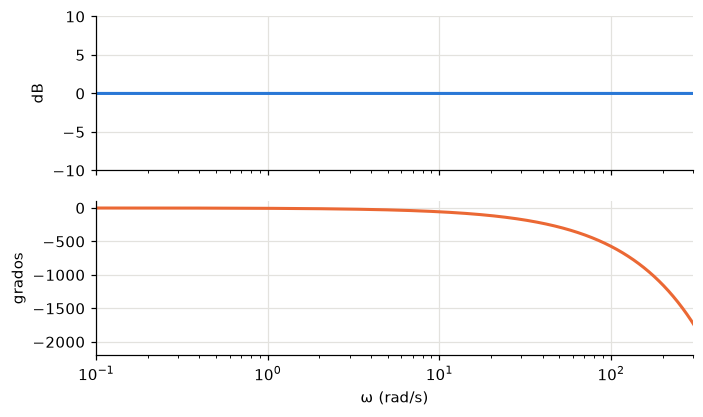

In [7]:
T = 0.1
D = lambda w: np.exp(-1j * np.asarray(w) * T)
for wv in (1, 10, 100):
    print(f"w = {wv:>4}: {db(D(wv)):.2f} dB, fase = {-np.degrees(wv*T):8.1f}°")
assert np.isclose(-np.degrees(10*T), -57.2958, atol=1e-3) and np.isclose(-np.degrees(100*T), -572.958, atol=1e-3)

fig, (m, p) = plt.subplots(2, 1, figsize=(7, 4), sharex=True)
m.semilogx(w, db(D(w)), color=AZUL, lw=2); m.set_ylim(-10, 10); m.set_ylabel("dB")
p.semilogx(w, -np.degrees(w*T), color=NARANJA, lw=2); p.set_xlim(0.1, 300); p.set_ylim(-2200, 100)
p.set_ylabel("grados"); p.set_xlabel("ω (rad/s)")
plt.show()

Por eso un retardo (o un muestreo lento, Paso 10) es tan dañino: no cambia la ganancia, pero se come el margen de fase a alta frecuencia.

## 6. Ejercicio del Paso 4

$P(s)=\dfrac{40(s+1)}{s(s+10)}$.

1. Escríbela en forma normalizada e identifica los factores.
2. Pendientes de la magnitud antes de $\omega=1$, entre 1 y 10, y después de 10.
3. Calcula **exactamente** $|P(j1)|$ en dB y $\angle P(j1)$ sumando factores.

**Tu turno.**

In [8]:
Q = lambda s: 40*(s + 1) / (s*(s + 10))
# 1) forma normalizada: K, factores
# 2) pendientes
# 3) |Q(j1)| en dB y fase, sumando factores y comparando con Q(1j)
# escribe aquí tu código

In [9]:
print("Forma normalizada: P = 4 (1 + s) / ( s (1 + s/10) )  ->  K = 4 (12.04 dB), un integrador, un cero en 1, un polo en 10")
asy = lambda x: asintota_db(x, 4, 1, ceros=[1], polos=[10])
for a, b in [(0.01, 0.1), (2, 5), (20, 200)]:      # tramos lejos de los codos
    pend = (asy(b) - asy(a)) / np.log10(b / a)
    print(f"entre w = {a} y {b}: pendiente {pend:6.1f} dB/dec")

s = 1j
fac = [4 + 0j, 1/s, 1 + s, 1/(1 + s/10)]
suma_db = sum(db(f) for f in fac); suma_fase = sum(np.degrees(np.angle(f)) for f in fac)
print(f"suma de factores: {suma_db:.2f} dB, {suma_fase:.2f}°")
print(f"directo         : {db(Q(s)):.2f} dB, {np.degrees(np.angle(Q(s))):.2f}°")
assert np.isclose(suma_db, db(Q(s))) and np.isclose(suma_fase, np.degrees(np.angle(Q(s))))

Forma normalizada: P = 4 (1 + s) / ( s (1 + s/10) )  ->  K = 4 (12.04 dB), un integrador, un cero en 1, un polo en 10
entre w = 0.01 y 0.1: pendiente  -20.0 dB/dec
entre w = 2 y 5: pendiente    0.0 dB/dec
entre w = 20 y 200: pendiente  -20.0 dB/dec
suma de factores: 15.01 dB, -50.71°
directo         : 15.01 dB, -50.71°


## 7. Resumen

- $\text{dB}=20\log_{10}|\cdot|$: **×2 = 6 dB, ×10 = 20 dB, ×$1/\sqrt2$ = −3 dB**.
- En dB y grados, un producto de factores es una **suma**: se dibuja factor a factor y se suma.
- Bloques: ganancia (recta), integrador ($-20$ dB/dec, $-90^\circ$), polo (codo, $-3$ dB, $-45^\circ$), cero (lo contrario).
- Un retardo $e^{-sT}$ mantiene 0 dB y resta $\omega T$ rad de fase sin límite.

**Siguiente:** Paso 5, realimentación: $L$, $T=\frac{L}{1+L}$ y $S=\frac1{1+L}$.